# 1. Data Loading and Preparation

In [27]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr


In [28]:
# Load the exported the datasets
ndvi = pd.read_csv("data/Alghero_Nurra_Monthly_NDVI_2020_2025.csv")
climate = pd.read_csv("data/Alghero_Nurra_Monthly_Climate_2020_2025.csv")

# Merge datasets by date
df = pd.merge(ndvi, climate, on=['date', 'year', 'month'],
    how='outer', validate="one_to_one", indicator=True)

# Sort the merged dataset chronologically
df = df.sort_values('date').reset_index(drop=True)

# Convert date to datetime
df['date'] = pd.to_datetime(df['date'])

# Check monthly continuity
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

actual_dates = df["date"].dt.to_period("M").dt.to_timestamp()

missing_months = expected_dates.difference(actual_dates)

if missing_months.empty:
    print("Monthly continuity: OK")
else:
    print("Missing months:", missing_months.strftime("%Y-%m").tolist())

Monthly continuity: OK


In [29]:
# Check the merged dataset
print("Datset shape:", df.shape)
print("\nMerge status:")
print(df["_merge"].value_counts())

# Check for missing values
print("\nMissing values:")
print(df.isna().sum())

print("\nMonths with missing NDVI:")
print(df.loc[df["NDVI_mean"].isna(), ["date", "NDVI_mean"]])

Datset shape: (72, 8)

Merge status:
_merge
both          72
left_only      0
right_only     0
Name: count, dtype: int64

Missing values:
date                0
year                0
month               0
NDVI_mean           2
precipitation_mm    0
temperature_C       0
soil_moisture       0
_merge              0
dtype: int64

Months with missing NDVI:
         date  NDVI_mean
11 2020-12-01        NaN
50 2024-03-01        NaN


In [30]:
# Check data types
print(df.dtypes)

# Descriptive statistics
print(df[["NDVI_mean", "precipitation_mm", "temperature_C", "soil_moisture"]].describe())

date                datetime64[ns]
year                         int64
month                        int64
NDVI_mean                  float64
precipitation_mm           float64
temperature_C              float64
soil_moisture              float64
_merge                    category
dtype: object
       NDVI_mean  precipitation_mm  temperature_C  soil_moisture
count  70.000000         72.000000      72.000000      72.000000
mean    0.536837         41.973861      17.823056       0.204350
std     0.124672         34.739916       5.617050       0.091929
min     0.350120          0.587284       9.681451       0.085368
25%     0.407395         15.981926      12.445526       0.118661
50%     0.565229         36.461381      16.516365       0.189788
75%     0.644108         63.548097      23.175737       0.278944
max     0.721382        144.363612      27.170034       0.394215


In [31]:
# Check chronological coverage
print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("Number of records:", len(df))
print("Number of unique months:", df["date"].nunique())

# Check monthly intervals
print("Monthly_intervals:")
print(df["date"].diff().value_counts())

Start date: 2020-01-01 00:00:00
End date: 2025-12-01 00:00:00
Number of records: 72
Number of unique months: 72
Monthly_intervals:
date
31 days    41
30 days    24
28 days     4
29 days     2
Name: count, dtype: int64


# 2. Monthly time series

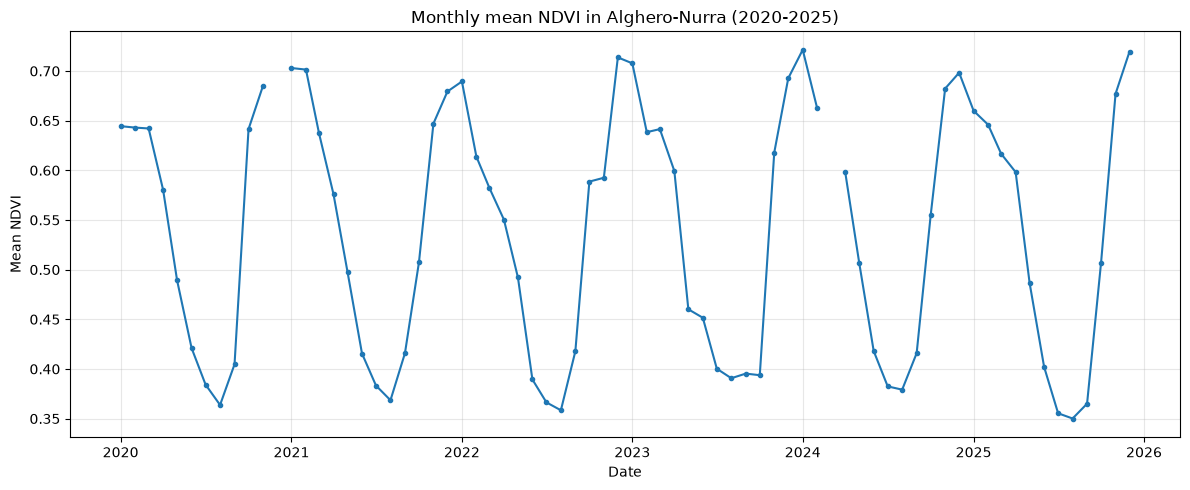

In [32]:
# Plot monthly mean NDVI over time
plt.figure(figsize=(12, 5))
plt.plot(df['date'], df['NDVI_mean'], marker ='o', markersize=3)
plt.xlabel("Date")
plt.ylabel("Mean NDVI")
plt.title("Monthly mean NDVI in Alghero-Nurra (2020-2025)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

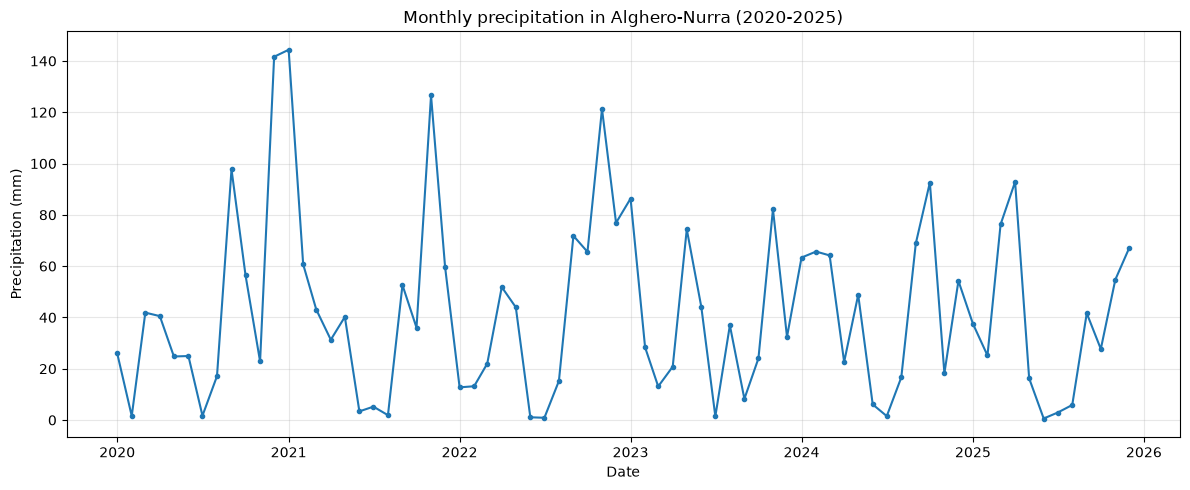

In [33]:
# Plot monthly precipitation over time
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["precipitation_mm"], marker="o", markersize=3)
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.title("Monthly precipitation in Alghero-Nurra (2020-2025)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

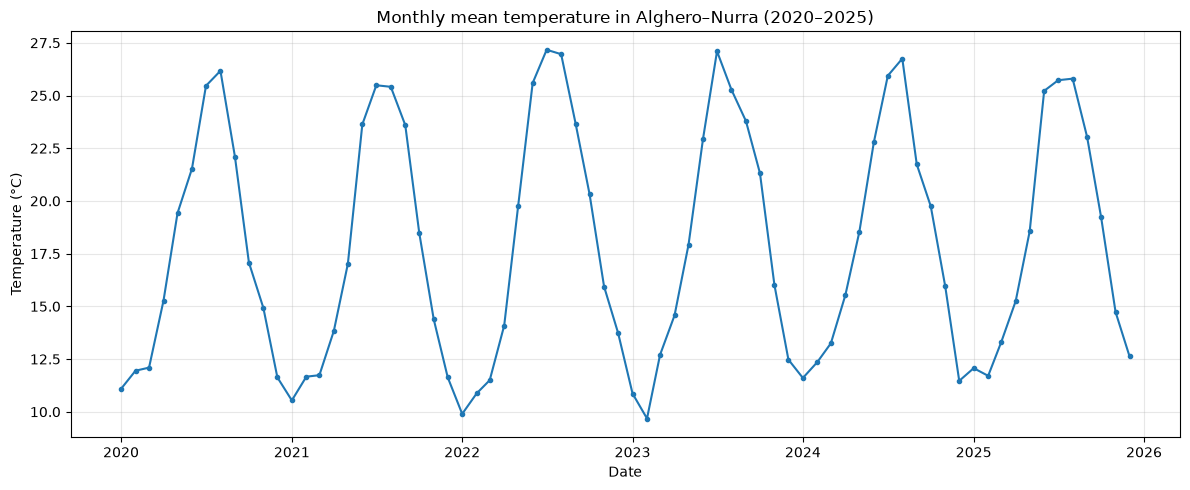

In [34]:
# Plot monthly mean temperature over time
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["temperature_C"], marker="o", markersize=3)
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Monthly mean temperature in Alghero–Nurra (2020–2025)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

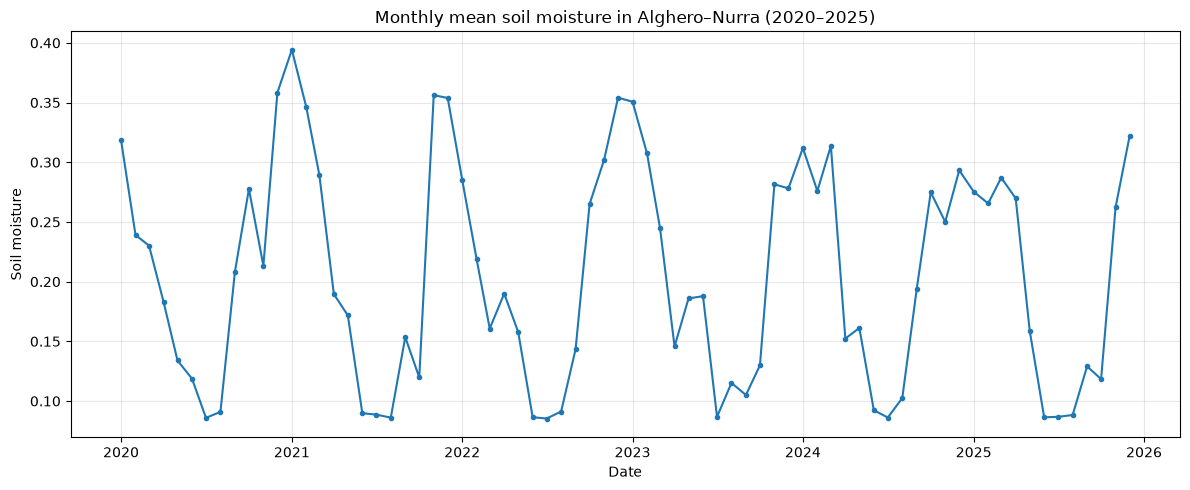

In [35]:
# Plot monthly soil moisture over time
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["soil_moisture"], marker="o", markersize=3)
plt.xlabel("Date")
plt.ylabel("Soil moisture")
plt.title("Monthly mean soil moisture in Alghero–Nurra (2020–2025)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Monthly Anomaly Calculation

In [36]:
# Calculate monthly anomalies
variables = {
    "NDVI_mean": "NDVI_anomaly",
    "precipitation_mm": "precipitation_anomaly",
    "temperature_C": "temperature_anomaly",
    "soil_moisture": "soil_moisture_anomaly"
}

for source, anomaly in variables.items():
    df[anomaly] = df[source] - df.groupby("month")[source].transform("mean")

print("Missing values in anomaly columns:")
print(df[list(variables.values())].isna().sum())

print("\nExample NDVI anomalies:")
print(df[["date", "NDVI_mean", "NDVI_anomaly"]].head(15))

Missing values in anomaly columns:
NDVI_anomaly             2
precipitation_anomaly    0
temperature_anomaly      0
soil_moisture_anomaly    0
dtype: int64

Example NDVI anomalies:
         date  NDVI_mean  NDVI_anomaly
0  2020-01-01   0.644464     -0.043199
1  2020-02-01   0.643038     -0.007793
2  2020-03-01   0.642142      0.018210
3  2020-04-01   0.580374     -0.003340
4  2020-05-01   0.489148      0.000457
5  2020-06-01   0.421052      0.004764
6  2020-07-01   0.384223      0.005563
7  2020-08-01   0.363742     -0.004696
8  2020-09-01   0.404678      0.002240
9  2020-10-01   0.641494      0.109340
10 2020-11-01   0.685171      0.034843
11 2020-12-01        NaN           NaN
12 2021-01-01   0.702999      0.015336
13 2021-02-01   0.701419      0.050588
14 2021-03-01   0.637211      0.013279


# 4. Contemporaneous Correlations

In [37]:
# Define climate anomaly variation
climate_anomalies = [
    "precipitation_anomaly",
    "temperature_anomaly",
    "soil_moisture_anomaly"
]

contemporaneous_results = []

for variable in climate_anomalies:
    data = df[["NDVI_anomaly", variable]].dropna()
    r, p = pearsonr(data[variable], data["NDVI_anomaly"])

    contemporaneous_results.append({
        "Climate variable": variable.replace("_anomaly", "").replace("_", " ").title(),
        "Observations": len(data),
        "Pearson r": r,
        "p-value": p
    })

contemporaneous_results_df = pd.DataFrame(contemporaneous_results)
print(contemporaneous_results_df.round(4).to_string(index=False))

Climate variable  Observations  Pearson r  p-value
   Precipitation            70     0.1817   0.1322
     Temperature            70    -0.2482   0.0383
   Soil Moisture            70     0.4690   0.0000


# 5. Lagged Climate-NDVI Analysis

In [38]:
# Create lagged climate anomaly variables
df["precipitation_anomaly_lag1"] = df["precipitation_anomaly"].shift(1)
df["precipitation_anomaly_lag2"] = df["precipitation_anomaly"].shift(2)
df["temperature_anomaly_lag1"] = df["temperature_anomaly"].shift(1)
df["soil_moisture_anomaly_lag1"] = df["soil_moisture_anomaly"].shift(1)

# Calculate Pearson correlations for the precipitation lags
lagged_precipitation_results = []

for lag, variable in [
    (1, "precipitation_anomaly_lag1"),
    (2, "precipitation_anomaly_lag2")
]:
    data = df[["NDVI_anomaly", variable]].dropna()
    r, p = pearsonr(data[variable], data["NDVI_anomaly"])

    lagged_precipitation_results.append({
        "Lag (months)": lag,
        "Observations": len(data),
        "Pearson r": r,
        "p-value": p,
        "R-squared": r ** 2
    })

lagged_precipitation_results_df = pd.DataFrame(lagged_precipitation_results)
print(lagged_precipitation_results_df.round(4).to_string(index=False))

 Lag (months)  Observations  Pearson r  p-value  R-squared
            1            69     0.4243   0.0003     0.1801
            2            68     0.1957   0.1097     0.0383


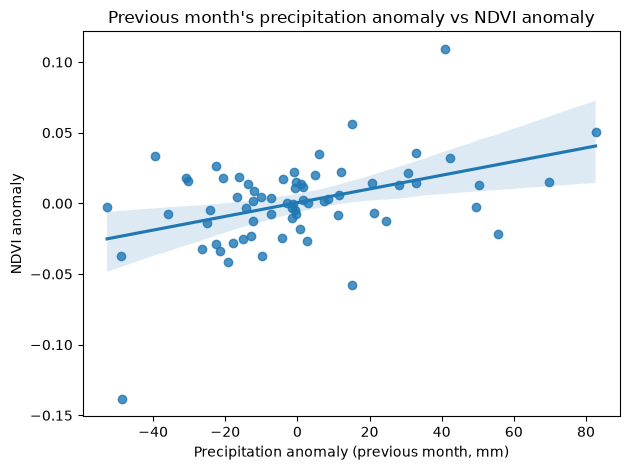

In [39]:
# Plot the one-month precipitation lag against current NDVI anomaly
data = df[["precipitation_anomaly_lag1", "NDVI_anomaly"]].dropna()

sns.regplot(
    data=data,
    x="precipitation_anomaly_lag1",
    y="NDVI_anomaly",
    ci=95
)
plt.xlabel("Precipitation anomaly (previous month, mm)")
plt.ylabel("NDVI anomaly")
plt.title("Previous month's precipitation anomaly vs NDVI anomaly")
plt.tight_layout()
plt.show()

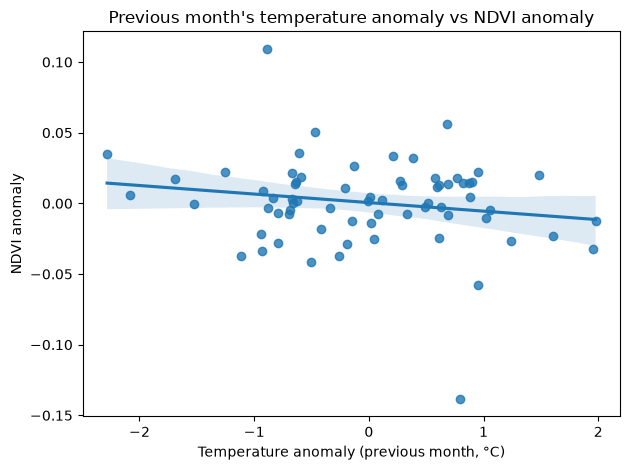

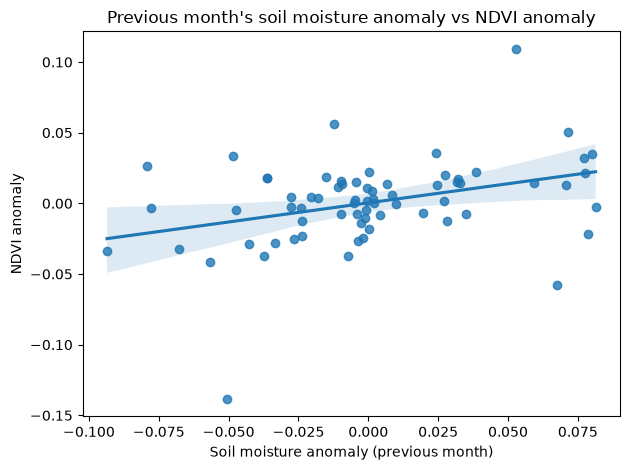

In [40]:
# Plot the one-month temperature and soil moisture lags against NDVI anomaly
for variable, label, unit in [
    ("temperature_anomaly_lag1", "Temperature", "°C"),
    ("soil_moisture_anomaly_lag1", "Soil moisture", "")
]:
    data = df[[variable, "NDVI_anomaly"]].dropna()

    sns.regplot(
        data=data,
        x=variable,
        y="NDVI_anomaly",
        ci=95
    )
    plt.xlabel(f"{label} anomaly (previous month{', ' + unit if unit else ''})")
    plt.ylabel("NDVI anomaly")
    plt.title(f"Previous month's {label.lower()} anomaly vs NDVI anomaly")
    plt.tight_layout()
    plt.show()

In [41]:
# Compare lag-1 correlations across climate variables
lag1_results = []

for variable, label in [
    ("precipitation_anomaly_lag1", "Precipitation"),
    ("temperature_anomaly_lag1", "Temperature"),
    ("soil_moisture_anomaly_lag1", "Soil moisture")
]:
    data = df[["NDVI_anomaly", variable]].dropna()
    r, p = pearsonr(data[variable], data["NDVI_anomaly"])

    lag1_results.append({
        "Climate variable": label,
        "Observations": len(data),
        "Pearson r": r,
        "p-value": p,
        "R-squared": r ** 2
    })

results_df = pd.DataFrame(lag1_results)
print(results_df.round(4).to_string(index=False))

Climate variable  Observations  Pearson r  p-value  R-squared
   Precipitation            69     0.4243   0.0003     0.1801
     Temperature            69    -0.1785   0.1424     0.0318
   Soil moisture            69     0.3572   0.0026     0.1276


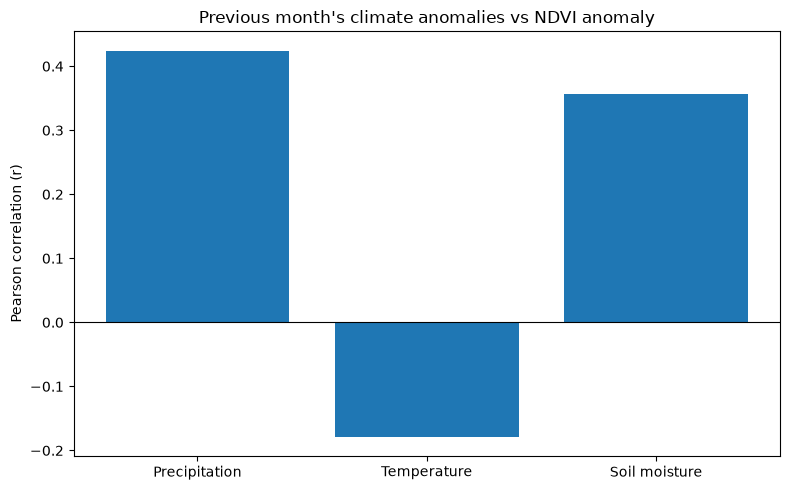

In [42]:
# Plot lag-1 Pearson correlations
plt.figure(figsize=(8, 5))
plt.bar(results_df["Climate variable"], results_df["Pearson r"])
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Pearson correlation (r)")
plt.title("Previous month's climate anomalies vs NDVI anomaly")
plt.tight_layout()
plt.show()

# 6. Seasonal Correlation Analysis

In [43]:
# Assign a meteorological season to each observation
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    return "Autumn"

df["season"] = df["month"].apply(get_season)
seasons = ["Winter", "Spring", "Summer", "Autumn"]

# Summarize seasonal lag-1 correlations for precipitation and soil moisture
seasonal_results = []

for season in seasons:
    for variable, label in [
        ("precipitation_anomaly_lag1", "Precipitation"),
        ("soil_moisture_anomaly_lag1", "Soil moisture"),
        ("temperature_anomaly_lag1", "Temperature")
    ]:
        data = df.loc[
            df["season"] == season,
            ["NDVI_anomaly", variable]
        ].dropna()

        r, p = pearsonr(data[variable], data["NDVI_anomaly"])

        seasonal_results.append({
            "Season": season,
            "Climate variable": label,
            "Observations": len(data),
            "Pearson r": r,
            "p-value": p,
            "R-squared": r ** 2
        })

seasonal_results_df = pd.DataFrame(seasonal_results)
print(seasonal_results_df.round(4).to_string(index=False))

Season Climate variable  Observations  Pearson r  p-value  R-squared
Winter    Precipitation            16     0.3750   0.1524     0.1406
Winter    Soil moisture            16     0.2507   0.3489     0.0629
Winter      Temperature            16     0.2924   0.2718     0.0855
Spring    Precipitation            17     0.2421   0.3491     0.0586
Spring    Soil moisture            17     0.5458   0.0234     0.2979
Spring      Temperature            17     0.3420   0.1791     0.1169
Summer    Precipitation            18     0.6123   0.0069     0.3749
Summer    Soil moisture            18     0.5037   0.0331     0.2537
Summer      Temperature            18    -0.4040   0.0963     0.1632
Autumn    Precipitation            18     0.6885   0.0016     0.4740
Autumn    Soil moisture            18     0.3512   0.1530     0.1233
Autumn      Temperature            18    -0.4185   0.0839     0.1751


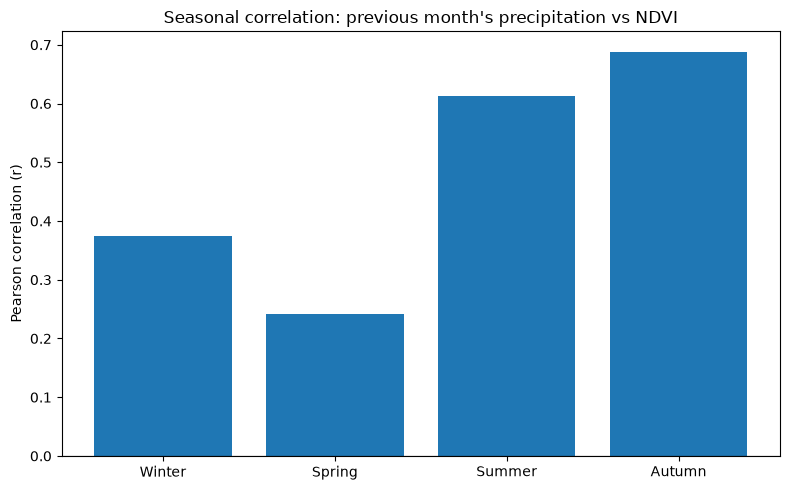

In [44]:
# Plot seasonal precipitation correlations
precipitation_seasonal = (
    seasonal_results_df[
        seasonal_results_df["Climate variable"] == "Precipitation"
    ].set_index("Season").reindex(seasons)
)

plt.figure(figsize=(8, 5))
plt.bar(seasons, precipitation_seasonal["Pearson r"])
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Pearson correlation (r)")
plt.title("Seasonal correlation: previous month's precipitation vs NDVI")
plt.tight_layout()
plt.show()

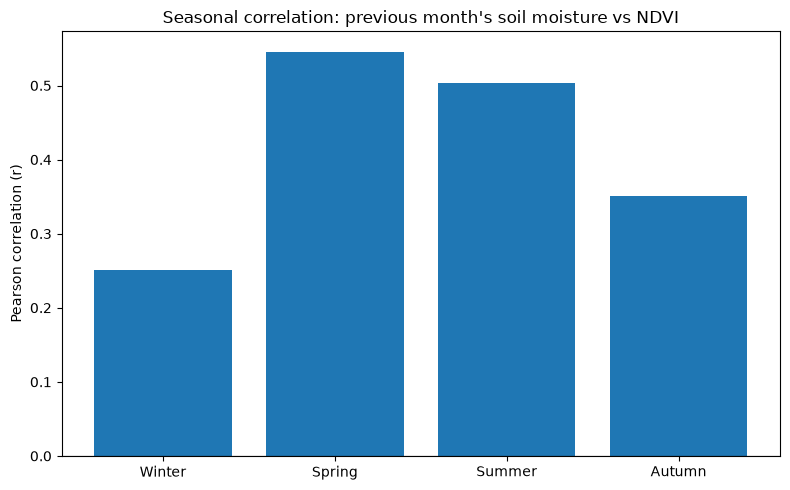

In [45]:
# Plot seasonal soil moisture correlations
soil_moisture_seasonal = (
    seasonal_results_df[
        seasonal_results_df["Climate variable"] == "Soil moisture"
    ].set_index("Season").reindex(seasons)
)

plt.figure(figsize=(8, 5))
plt.bar(seasons, soil_moisture_seasonal["Pearson r"])
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Pearson correlation (r)")
plt.title("Seasonal correlation: previous month's soil moisture vs NDVI")
plt.tight_layout()
plt.show()

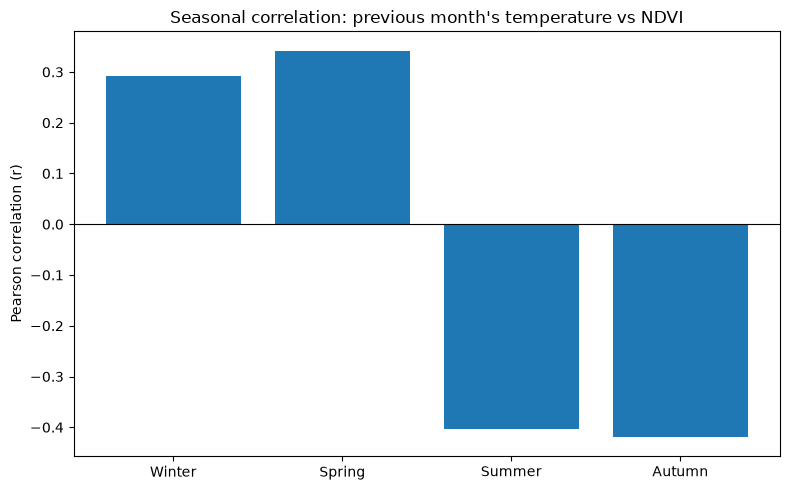

In [46]:
# Plot seasonal temperature correlations
temperature_seasonal = (
    seasonal_results_df[
        seasonal_results_df["Climate variable"] == "Temperature"
    ].set_index("Season").reindex(seasons)
)

plt.figure(figsize=(8, 5))
plt.bar(seasons, temperature_seasonal["Pearson r"])
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Pearson correlation (r)")
plt.title("Seasonal correlation: previous month's temperature vs NDVI")
plt.tight_layout()
plt.show()

# 7. Sensitivity Analysis: October 2023

In [47]:
# Inspect the five lowest and highest NDVI anomalies
print("Lowest NDVI anomalies:")
print(
    df.nsmallest(5, "NDVI_anomaly")[
        ["date", "NDVI_mean", "NDVI_anomaly", "precipitation_anomaly_lag1"]
    ].to_string(index=False)
)

print("\nHighest NDVI anomalies:")
print(
    df.nlargest(5, "NDVI_anomaly")[
        ["date", "NDVI_mean", "NDVI_anomaly", "precipitation_anomaly_lag1"]
    ].to_string(index=False)
)

Lowest NDVI anomalies:
      date  NDVI_mean  NDVI_anomaly  precipitation_anomaly_lag1
2023-10-01   0.393725     -0.138429                  -48.567790
2022-11-01   0.592504     -0.057824                   15.195552
2020-01-01   0.644464     -0.043199                         NaN
2022-03-01   0.582155     -0.041777                  -19.271479
2025-09-01   0.365025     -0.037413                   -9.735023

Highest NDVI anomalies:
      date  NDVI_mean  NDVI_anomaly  precipitation_anomaly_lag1
2020-10-01   0.641494      0.109340                   40.922111
2022-10-01   0.588651      0.056497                   15.000837
2021-02-01   0.701419      0.050588                   82.658142
2023-06-01   0.451572      0.035285                   32.967585
2020-11-01   0.685171      0.034843                    5.986093


Original: r = 0.4243, p = 0.000279
Excluding October 2023: r = 0.3705, p = 0.001869


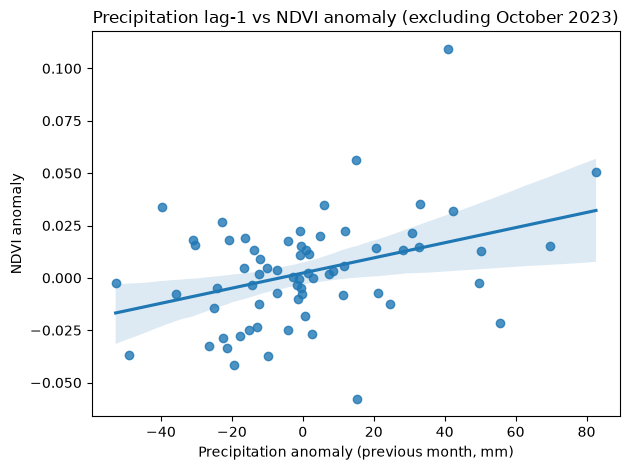

In [48]:
# Compare the original correlation with a sensitivity analysis excluding October 2023
data = df[["date", "precipitation_anomaly_lag1", "NDVI_anomaly"]].dropna()

r_original, p_original = pearsonr(
    data["precipitation_anomaly_lag1"],
    data["NDVI_anomaly"]
)

data_filtered = data[data["date"] != pd.Timestamp("2023-10-01")]

r_filtered, p_filtered = pearsonr(
    data_filtered["precipitation_anomaly_lag1"],
    data_filtered["NDVI_anomaly"]
)

print(f"Original: r = {r_original:.4f}, p = {p_original:.6f}")
print(f"Excluding October 2023: r = {r_filtered:.4f}, p = {p_filtered:.6f}")

sns.regplot(
    data=data_filtered,
    x="precipitation_anomaly_lag1",
    y="NDVI_anomaly",
    ci=95
)
plt.xlabel("Precipitation anomaly (previous month, mm)")
plt.ylabel("NDVI anomaly")
plt.title("Precipitation lag-1 vs NDVI anomaly (excluding October 2023)")
plt.tight_layout()
plt.show()